# E-Commerce Text Classification using GRU with Different Embeddings

## Overview
This notebook implements a text classification pipeline to categorize e-commerce product descriptions into four classes:
- Electronics
- Household
- Books
- Clothing & Accessories

We train three models with identical GRU architecture but different word embeddings:
1. **Word2Vec CBOW** + GRU
2. **Word2Vec Skip-gram** + GRU
3. **FastText (pretrained)** + GRU

## Embedding Approaches

### 1. Word2Vec CBOW (Continuous Bag of Words)
- Predicts target word from context words
- Faster to train
- Works well with frequent words
- Better for syntactic tasks

### 2. Word2Vec Skip-gram
- Predicts context words from target word
- Slower but works better with small datasets
- Better representation for rare words
- Superior for semantic tasks

### 3. FastText
- Extension of Word2Vec that uses subword information
- Handles out-of-vocabulary words by breaking them into character n-grams
- More robust for morphologically rich languages and typos
- Pretrained embeddings leverage large external corpora

## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

from gensim.models import Word2Vec, FastText
import gensim.downloader as api

import re
from nltk.tokenize import word_tokenize
import nltk

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.19.0
GPU available: []


## 2. Load and Explore Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# df = pd.read_csv('ecommerceDataset.csv', header=None, names=['category', 'text'])

df = pd.read_csv(
    '/content/drive/MyDrive/ecommerceDataset.csv',
    header=None,
    names=['category', 'text']
)


print("Dataset shape:", df.shape)
print("\nFirst few rows:")
print(df.head())
print("\nClass distribution:")
print(df['category'].value_counts())
print("\nDataset info:")
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset shape: (50425, 2)

First few rows:
    category                                               text
0  Household  Paper Plane Design Framed Wall Hanging Motivat...
1  Household  SAF 'Floral' Framed Painting (Wood, 30 inch x ...
2  Household  SAF 'UV Textured Modern Art Print Framed' Pain...
3  Household  SAF Flower Print Framed Painting (Synthetic, 1...
4  Household  Incredible Gifts India Wooden Happy Birthday U...

Class distribution:
category
Household                 19313
Books                     11820
Electronics               10621
Clothing & Accessories     8671
Name: count, dtype: int64

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50425 entries, 0 to 50424
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   category  50425 non-null  object
 1   text      50424 no

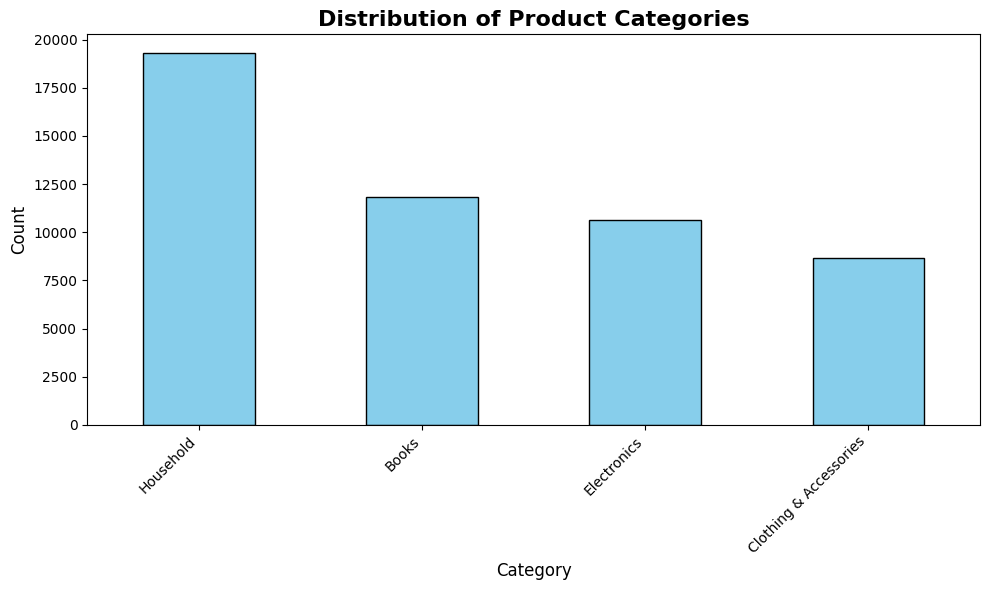


Text length statistics:
count    50425.000000
mean       114.182053
std        157.806212
min          1.000000
25%         34.000000
50%         78.000000
75%        152.000000
max       8181.000000
Name: text_length, dtype: float64


In [ ]:
plt.figure(figsize=(10, 6))
df['category'].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Distribution of Product Categories', fontsize=16, fontweight='bold')
plt.xlabel('Category', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

df['text_length'] = df['text'].apply(lambda x: len(str(x).split()))
print("\nText length statistics:")
print(df['text_length'].describe())

## 3. Data Preprocessing

In [8]:
def preprocess_text(text):
    """
    Preprocesses text by:
    - Converting to lowercase
    - Removing special characters and digits
    - Removing extra whitespace
    """
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)  # Remove special chars and digits
    text = re.sub(r'\s+', ' ', text).strip()  # Remove extra whitespace
    return text

# Apply preprocessing
print("Preprocessing text...")
df['cleaned_text'] = df['text'].apply(preprocess_text)

# Remove empty texts
df = df[df['cleaned_text'].str.len() > 0].reset_index(drop=True)

print(f"Dataset size after cleaning: {len(df)}")
print("\nSample cleaned texts:")
for i in range(3):
    print(f"\nOriginal: {df['text'].iloc[i][:100]}...")
    print(f"Cleaned: {df['cleaned_text'].iloc[i][:100]}...")

Preprocessing text...
Dataset size after cleaning: 50425

Sample cleaned texts:

Original: Paper Plane Design Framed Wall Hanging Motivational Office Decor Art Prints (8.7 X 8.7 inch) - Set o...
Cleaned: paper plane design framed wall hanging motivational office decor art prints x inch set of painting m...

Original: SAF 'Floral' Framed Painting (Wood, 30 inch x 10 inch, Special Effect UV Print Textured, SAO297) Pai...
Cleaned: saf floral framed painting wood inch x inch special effect uv print textured sao painting made up in...

Original: SAF 'UV Textured Modern Art Print Framed' Painting (Synthetic, 35 cm x 50 cm x 3 cm, Set of 3) Color...
Cleaned: saf uv textured modern art print framed painting synthetic cm x cm x cm set of colormulticolor size ...


In [9]:
# Encode labels
category_mapping = {
    'Electronics': 0,
    'Household': 1,
    'Books': 2,
    'Clothing & Accessories': 3
}

df['label'] = df['category'].map(category_mapping)

print("Label encoding:")
for cat, label in category_mapping.items():
    print(f"{cat}: {label}")

# Split data into train and validation sets (80-20 split)
X = df['cleaned_text'].values
y = df['label'].values

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTraining samples: {len(X_train)}")
print(f"Validation samples: {len(X_val)}")
print(f"\nTraining set class distribution:")
unique, counts = np.unique(y_train, return_counts=True)
for u, c in zip(unique, counts):
    print(f"  Class {u}: {c} samples")

Label encoding:
Electronics: 0
Household: 1
Books: 2
Clothing & Accessories: 3

Training samples: 40340
Validation samples: 10085

Training set class distribution:
  Class 0: 8497 samples
  Class 1: 15450 samples
  Class 2: 9456 samples
  Class 3: 6937 samples


## 4. Tokenization and Sequence Padding

In [ ]:
# Hyperparameters (consistent across all models)
MAX_VOCAB_SIZE = 20000 
EMBEDDING_DIM = 100
MAX_SEQUENCE_LENGTH = 50 
NUM_CLASSES = 4

# Tokenize the text using Keras Tokenizer (word-level tokenization)
tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train)

# Convert texts to sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)

# Pad sequences to fixed length
X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_SEQUENCE_LENGTH,
                             padding='post', truncating='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=MAX_SEQUENCE_LENGTH,
                          padding='post', truncating='post')

# Convert labels to categorical (one-hot encoding)
y_train_cat = to_categorical(y_train, num_classes=NUM_CLASSES)
y_val_cat = to_categorical(y_val, num_classes=NUM_CLASSES)

print(f"Vocabulary size: {len(tokenizer.word_index)}")
print(f"Training sequences shape: {X_train_pad.shape}")
print(f"Validation sequences shape: {X_val_pad.shape}")
print(f"Training labels shape: {y_train_cat.shape}")
print(f"Validation labels shape: {y_val_cat.shape}")

Vocabulary size: 89578
Training sequences shape: (40340, 50)
Validation sequences shape: (10085, 50)
Training labels shape: (40340, 4)
Validation labels shape: (10085, 4)


## 5. Create Word Embeddings

### 5.1 Word2Vec CBOW Embeddings

In [11]:
# Prepare tokenized sentences for Word2Vec training
train_sentences = [text.split() for text in X_train]

print(f"Training Word2Vec on {len(train_sentences)} sentences...")

# Train Word2Vec CBOW model
# sg=0 means CBOW (Continuous Bag of Words)
w2v_cbow_model = Word2Vec(
    sentences=train_sentences,
    vector_size=EMBEDDING_DIM,
    window=5,
    min_count=2,
    workers=4,
    sg=0,  # CBOW
    seed=42
)

print(f"Word2Vec CBOW vocabulary size: {len(w2v_cbow_model.wv)}")
print("Sample word vectors (first 5 values):")
sample_words = list(w2v_cbow_model.wv.index_to_key)[:3]
for word in sample_words:
    print(f"  {word}: {w2v_cbow_model.wv[word][:5]}")

Training Word2Vec on 40340 sentences...
Word2Vec CBOW vocabulary size: 61928
Sample word vectors (first 5 values):
  the: [ 0.889589    0.27268133 -0.42218828  0.79800683  0.11524607]
  and: [-0.21133697 -0.53515655 -0.3523191  -0.7471922   0.08221699]
  of: [ 1.9944332   0.6873208  -1.2636383   0.13524553  1.2159802 ]


In [12]:
# Create embedding matrix for Word2Vec CBOW
vocab_size = min(MAX_VOCAB_SIZE, len(tokenizer.word_index)) + 1
embedding_matrix_cbow = np.zeros((vocab_size, EMBEDDING_DIM))

# Fill the embedding matrix with Word2Vec vectors
for word, idx in tokenizer.word_index.items():
    if idx < vocab_size:
        if word in w2v_cbow_model.wv:
            embedding_matrix_cbow[idx] = w2v_cbow_model.wv[word]
        else:
            # Random initialization for OOV words
            embedding_matrix_cbow[idx] = np.random.normal(0, 0.1, EMBEDDING_DIM)

print(f"CBOW Embedding matrix shape: {embedding_matrix_cbow.shape}")
print(f"Non-zero rows (covered words): {np.count_nonzero(embedding_matrix_cbow.sum(axis=1))}")

CBOW Embedding matrix shape: (20001, 100)
Non-zero rows (covered words): 20000


### 5.2 Word2Vec Skip-gram Embeddings

In [ ]:
print("Training Word2Vec Skip-gram model...")
w2v_skipgram_model = Word2Vec(
    sentences=train_sentences,
    vector_size=EMBEDDING_DIM,
    window=5,
    min_count=2,
    workers=4,
    sg=1,
    seed=42
)

print(f"Word2Vec Skip-gram vocabulary size: {len(w2v_skipgram_model.wv)}")

# Create embedding matrix for Word2Vec Skip-gram
embedding_matrix_skipgram = np.zeros((vocab_size, EMBEDDING_DIM))

for word, idx in tokenizer.word_index.items():
    if idx < vocab_size:
        if word in w2v_skipgram_model.wv:
            embedding_matrix_skipgram[idx] = w2v_skipgram_model.wv[word]
        else:
            # Random initialization for OOV words
            embedding_matrix_skipgram[idx] = np.random.normal(0, 0.1, EMBEDDING_DIM)

print(f"Skip-gram Embedding matrix shape: {embedding_matrix_skipgram.shape}")
print(f"Non-zero rows (covered words): {np.count_nonzero(embedding_matrix_skipgram.sum(axis=1))}")

Training Word2Vec Skip-gram model...
Word2Vec Skip-gram vocabulary size: 61928
Skip-gram Embedding matrix shape: (20001, 100)
Non-zero rows (covered words): 20000


### 5.3 FastText Pretrained Embeddings

In [ ]:
print("Loading pretrained FastText embeddings (this may take a few minutes)...")
try:
    # Try loading a smaller model first
    fasttext_model = api.load('glove-wiki-gigaword-100')  # 100-dimensional GloVe as alternative
    print("Loaded GloVe-100 embeddings as FastText alternative")
except:
    print("Could not load pretrained embeddings. Training FastText on our corpus instead...")
    # Train FastText on our corpus if pretrained model is not available
    fasttext_model = FastText(
        sentences=train_sentences,
        vector_size=EMBEDDING_DIM,
        window=5,
        min_count=2,
        workers=4,
        seed=42
    )
    print(f"Trained FastText model with vocabulary size: {len(fasttext_model.wv)}")

Loading pretrained FastText embeddings (this may take a few minutes)...
[==================================================] 100.0% 128.1/128.1MB downloaded
Loaded GloVe-100 embeddings as FastText alternative


In [ ]:
embedding_matrix_fasttext = np.zeros((vocab_size, EMBEDDING_DIM))

oov_count = 0
for word, idx in tokenizer.word_index.items():
    if idx < vocab_size:
        try:
            # Try to get the vector from the model
            if hasattr(fasttext_model, 'wv'):
                if word in fasttext_model.wv:
                    vector = fasttext_model.wv[word]
                    # If vector dimension doesn't match, take first EMBEDDING_DIM values
                    if len(vector) >= EMBEDDING_DIM:
                        embedding_matrix_fasttext[idx] = vector[:EMBEDDING_DIM]
                    else:
                        embedding_matrix_fasttext[idx][:len(vector)] = vector
                else:
                    # For FastText, we can get vectors for OOV words using subword info
                    if hasattr(fasttext_model.wv, 'get_vector'):
                        try:
                            vector = fasttext_model.wv.get_vector(word)
                            if len(vector) >= EMBEDDING_DIM:
                                embedding_matrix_fasttext[idx] = vector[:EMBEDDING_DIM]
                            else:
                                embedding_matrix_fasttext[idx][:len(vector)] = vector
                        except:
                            embedding_matrix_fasttext[idx] = np.random.normal(0, 0.1, EMBEDDING_DIM)
                            oov_count += 1
                    else:
                        embedding_matrix_fasttext[idx] = np.random.normal(0, 0.1, EMBEDDING_DIM)
                        oov_count += 1
            else:
                if word in fasttext_model:
                    vector = fasttext_model[word]
                    if len(vector) >= EMBEDDING_DIM:
                        embedding_matrix_fasttext[idx] = vector[:EMBEDDING_DIM]
                    else:
                        embedding_matrix_fasttext[idx][:len(vector)] = vector
                else:
                    embedding_matrix_fasttext[idx] = np.random.normal(0, 0.1, EMBEDDING_DIM)
                    oov_count += 1
        except:
            embedding_matrix_fasttext[idx] = np.random.normal(0, 0.1, EMBEDDING_DIM)
            oov_count += 1

print(f"FastText Embedding matrix shape: {embedding_matrix_fasttext.shape}")
print(f"OOV words with random initialization: {oov_count}")
print(f"Non-zero rows (covered words): {np.count_nonzero(embedding_matrix_fasttext.sum(axis=1))}")

FastText Embedding matrix shape: (20001, 100)
OOV words with random initialization: 2743
Non-zero rows (covered words): 20000


## 6. Define GRU Model Architecture

In [ ]:
def create_gru_model(embedding_matrix, vocab_size, embedding_dim, max_seq_length, num_classes):
    """
    Creates a GRU-based text classification model.

    Architecture:
        - Embedding layer (initialized with pretrained embeddings)
        - GRU layer (128 units)
        - Dropout layer (0.5)
        - Dense layer with Softmax activation

    Args:
        embedding_matrix: Pretrained embedding weights
        vocab_size: Size of vocabulary
        embedding_dim: Dimension of embeddings
        max_seq_length: Maximum sequence length
        num_classes: Number of output classes

    Returns:
        Compiled Keras model
    """
    model = Sequential([
        # Embedding layer with pretrained weights
        Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim,
            weights=[embedding_matrix],
            input_length=max_seq_length,
            trainable=False  # Freeze embeddings
        ),

        # GRU layer
        GRU(units=128, dropout=0.2, recurrent_dropout=0.2),

        # Dropout for regularization
        Dropout(0.5),

        # Dense output layer with Softmax
        Dense(num_classes, activation='softmax')
    ])

    # Compile model
    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

print("GRU Model Architecture:")
print("=" * 60)
print("1. Embedding Layer (pretrained, frozen)")
print(f"   - Input dim: {vocab_size}")
print(f"   - Output dim: {EMBEDDING_DIM}")
print(f"   - Input length: {MAX_SEQUENCE_LENGTH}")
print("\n2. GRU Layer")
print("   - Units: 128")
print("   - Dropout: 0.2")
print("   - Recurrent dropout: 0.2")
print("\n3. Dropout Layer")
print("   - Rate: 0.5")
print("\n4. Dense Output Layer")
print(f"   - Units: {NUM_CLASSES}")
print("   - Activation: Softmax")
print("=" * 60)

GRU Model Architecture:
1. Embedding Layer (pretrained, frozen)
   - Input dim: 20001
   - Output dim: 100
   - Input length: 50

2. GRU Layer
   - Units: 128
   - Dropout: 0.2
   - Recurrent dropout: 0.2

3. Dropout Layer
   - Rate: 0.5

4. Dense Output Layer
   - Units: 4
   - Activation: Softmax


## 7. Train Models

### 7.1 Train Word2Vec CBOW + GRU Model

In [ ]:
BATCH_SIZE = 64
EPOCHS = 10
VALIDATION_SPLIT = 0.0 

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

print("Training Word2Vec CBOW + GRU Model...")
print("=" * 60)

model_cbow = create_gru_model(
    embedding_matrix_cbow,
    vocab_size,
    EMBEDDING_DIM,
    MAX_SEQUENCE_LENGTH,
    NUM_CLASSES
)

model_cbow.summary()

history_cbow = model_cbow.fit(
    X_train_pad, y_train_cat,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_val_pad, y_val_cat),
    callbacks=[early_stopping],
    verbose=1
)

print("\nWord2Vec CBOW + GRU training completed!")

Training Word2Vec CBOW + GRU Model...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │     2,000,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,000,100 (7.63 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,000,100 (7.63 MB)

Epoch 1/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 78s 116ms/step - accuracy: 0.7338 - loss: 0.6982 - val_accuracy: 0.9298 - val_loss: 0.2461
Epoch 2/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 73s 116ms/step - accuracy: 0.9313 - loss: 0.2560 - val_accuracy: 0.9426 - val_loss: 0.2107
Epoch 3/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 84s 119ms/step - accuracy: 0.9391 - loss: 0.2221 - val_accuracy: 0.9442 - val_loss: 0.1948
Epoch 4/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 75s 118ms/step - accuracy: 0.9442 - loss: 0.2005 - val_accuracy: 0.9499 - val_loss: 0.1782
Epoch 5/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 81s 117ms/step - accuracy: 0.9481 - loss: 0.1848 - val_accuracy: 0.9519 - val_loss: 0.1658
Epoch 6/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 80s 115ms/step - accuracy: 0.9507 - loss: 0.1740 - val_accuracy: 0.9550 - val_loss: 0.1572
Epoch 7/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 82s 115ms/step - accuracy: 0.9540 - loss: 0.1637 - val_accuracy: 0.9560 - val_loss: 0.1529
Epoch 8/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 83s 116ms/step - accuracy: 0.9578 - loss: 0

### 7.2 Train Word2Vec Skip-gram + GRU Model

In [ ]:
print("Training Word2Vec Skip-gram + GRU Model...")
print("=" * 60)

model_skipgram = create_gru_model(
    embedding_matrix_skipgram,
    vocab_size,
    EMBEDDING_DIM,
    MAX_SEQUENCE_LENGTH,
    NUM_CLASSES
)

model_skipgram.summary()

history_skipgram = model_skipgram.fit(
    X_train_pad, y_train_cat,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_val_pad, y_val_cat),
    callbacks=[early_stopping],
    verbose=1
)

print("\nWord2Vec Skip-gram + GRU training completed!")

Training Word2Vec Skip-gram + GRU Model...


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │     2,000,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,000,100 (7.63 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,000,100 (7.63 MB)

Epoch 1/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 79s 119ms/step - accuracy: 0.7695 - loss: 0.6258 - val_accuracy: 0.9111 - val_loss: 0.3020
Epoch 2/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 81s 118ms/step - accuracy: 0.9262 - loss: 0.2693 - val_accuracy: 0.9415 - val_loss: 0.2063
Epoch 3/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 75s 118ms/step - accuracy: 0.9395 - loss: 0.2169 - val_accuracy: 0.9458 - val_loss: 0.1918
Epoch 4/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 72s 115ms/step - accuracy: 0.9424 - loss: 0.2050 - val_accuracy: 0.9474 - val_loss: 0.1838
Epoch 5/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 84s 118ms/step - accuracy: 0.9450 - loss: 0.1942 - val_accuracy: 0.9481 - val_loss: 0.1812
Epoch 6/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 82s 118ms/step - accuracy: 0.9480 - loss: 0.1836 - val_accuracy: 0.9535 - val_loss: 0.1655
Epoch 7/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 74s 118ms/step - accuracy: 0.9506 - loss: 0.1725 - val_accuracy: 0.9537 - val_loss: 0.1616
Epoch 8/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 74s 117ms/step - accuracy: 0.9543 - loss: 0

### 7.3 Train FastText + GRU Model

In [ ]:
print("Training FastText + GRU Model...")
print("=" * 60)

model_fasttext = create_gru_model(
    embedding_matrix_fasttext,
    vocab_size,
    EMBEDDING_DIM,
    MAX_SEQUENCE_LENGTH,
    NUM_CLASSES
)

model_fasttext.summary()

history_fasttext = model_fasttext.fit(
    X_train_pad, y_train_cat,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_val_pad, y_val_cat),
    callbacks=[early_stopping],
    verbose=1
)

print("\nFastText + GRU training completed!")

Training FastText + GRU Model...


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │     2,000,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,000,100 (7.63 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,000,100 (7.63 MB)

Epoch 1/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 79s 117ms/step - accuracy: 0.7123 - loss: 0.7367 - val_accuracy: 0.9257 - val_loss: 0.2555
Epoch 2/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 75s 119ms/step - accuracy: 0.9150 - loss: 0.3003 - val_accuracy: 0.9308 - val_loss: 0.2267
Epoch 3/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 81s 118ms/step - accuracy: 0.9286 - loss: 0.2490 - val_accuracy: 0.9412 - val_loss: 0.1988
Epoch 4/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 73s 115ms/step - accuracy: 0.9368 - loss: 0.2198 - val_accuracy: 0.9489 - val_loss: 0.1795
Epoch 5/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 73s 116ms/step - accuracy: 0.9439 - loss: 0.2007 - val_accuracy: 0.9503 - val_loss: 0.1718
Epoch 6/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 82s 116ms/step - accuracy: 0.9498 - loss: 0.1831 - val_accuracy: 0.9552 - val_loss: 0.1613
Epoch 7/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 84s 119ms/step - accuracy: 0.9520 - loss: 0.1710 - val_accuracy: 0.9586 - val_loss: 0.1560
Epoch 8/10
631/631 ━━━━━━━━━━━━━━━━━━━━ 82s 118ms/step - accuracy: 0.9568 - loss: 0

## 8. Evaluate Models

In [ ]:
def evaluate_model(model, X_test, y_test, model_name):
    """
    Evaluates a trained model and returns metrics.

    Args:
        model: Trained Keras model
        X_test: Test features
        y_test: Test labels (one-hot encoded)
        model_name: Name of the model for display

    Returns:
        Dictionary containing evaluation metrics
    """
    print(f"\nEvaluating {model_name}...")
    print("=" * 60)

    y_pred_proba = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_pred_proba, axis=1)
    y_true = np.argmax(y_test, axis=1)

    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0
    )
    
    precision_per_class, recall_per_class, f1_per_class, _ = precision_recall_fscore_support(
        y_true, y_pred, average=None, zero_division=0
    )

    class_names = ['Electronics', 'Household', 'Books', 'Clothing & Accessories']
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    print(f"\nOverall Metrics:")
    print(f"  Accuracy:  {accuracy:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall:    {recall:.4f}")
    print(f"  F1-Score:  {f1:.4f}")

    return {
        'model': model_name,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'predictions': y_pred,
        'true_labels': y_true
    }

results_cbow = evaluate_model(model_cbow, X_val_pad, y_val_cat, "Word2Vec CBOW + GRU")
results_skipgram = evaluate_model(model_skipgram, X_val_pad, y_val_cat, "Word2Vec Skip-gram + GRU")
results_fasttext = evaluate_model(model_fasttext, X_val_pad, y_val_cat, "FastText + GRU")


Evaluating Word2Vec CBOW + GRU...

Classification Report:
                        precision    recall  f1-score   support

           Electronics       0.97      0.94      0.96      2124
             Household       0.95      0.98      0.96      3863
                 Books       0.97      0.95      0.96      2364
Clothing & Accessories       0.98      0.98      0.98      1734

              accuracy                           0.96     10085
             macro avg       0.97      0.96      0.96     10085
          weighted avg       0.96      0.96      0.96     10085


Overall Metrics:
  Accuracy:  0.9630
  Precision: 0.9633
  Recall:    0.9630
  F1-Score:  0.9630

Evaluating Word2Vec Skip-gram + GRU...

Classification Report:
                        precision    recall  f1-score   support

           Electronics       0.93      0.96      0.95      2124
             Household       0.96      0.96      0.96      3863
                 Books       0.97      0.94      0.96      2364
Clothin

## 9. Results Comparison


MODEL COMPARISON TABLE
                   Model  Accuracy  Precision   Recall  F1-Score
     Word2Vec CBOW + GRU  0.963014   0.963265 0.963014  0.962984
Word2Vec Skip-gram + GRU  0.959246   0.959542 0.959246  0.959292
          FastText + GRU  0.962221   0.962421 0.962221  0.962199


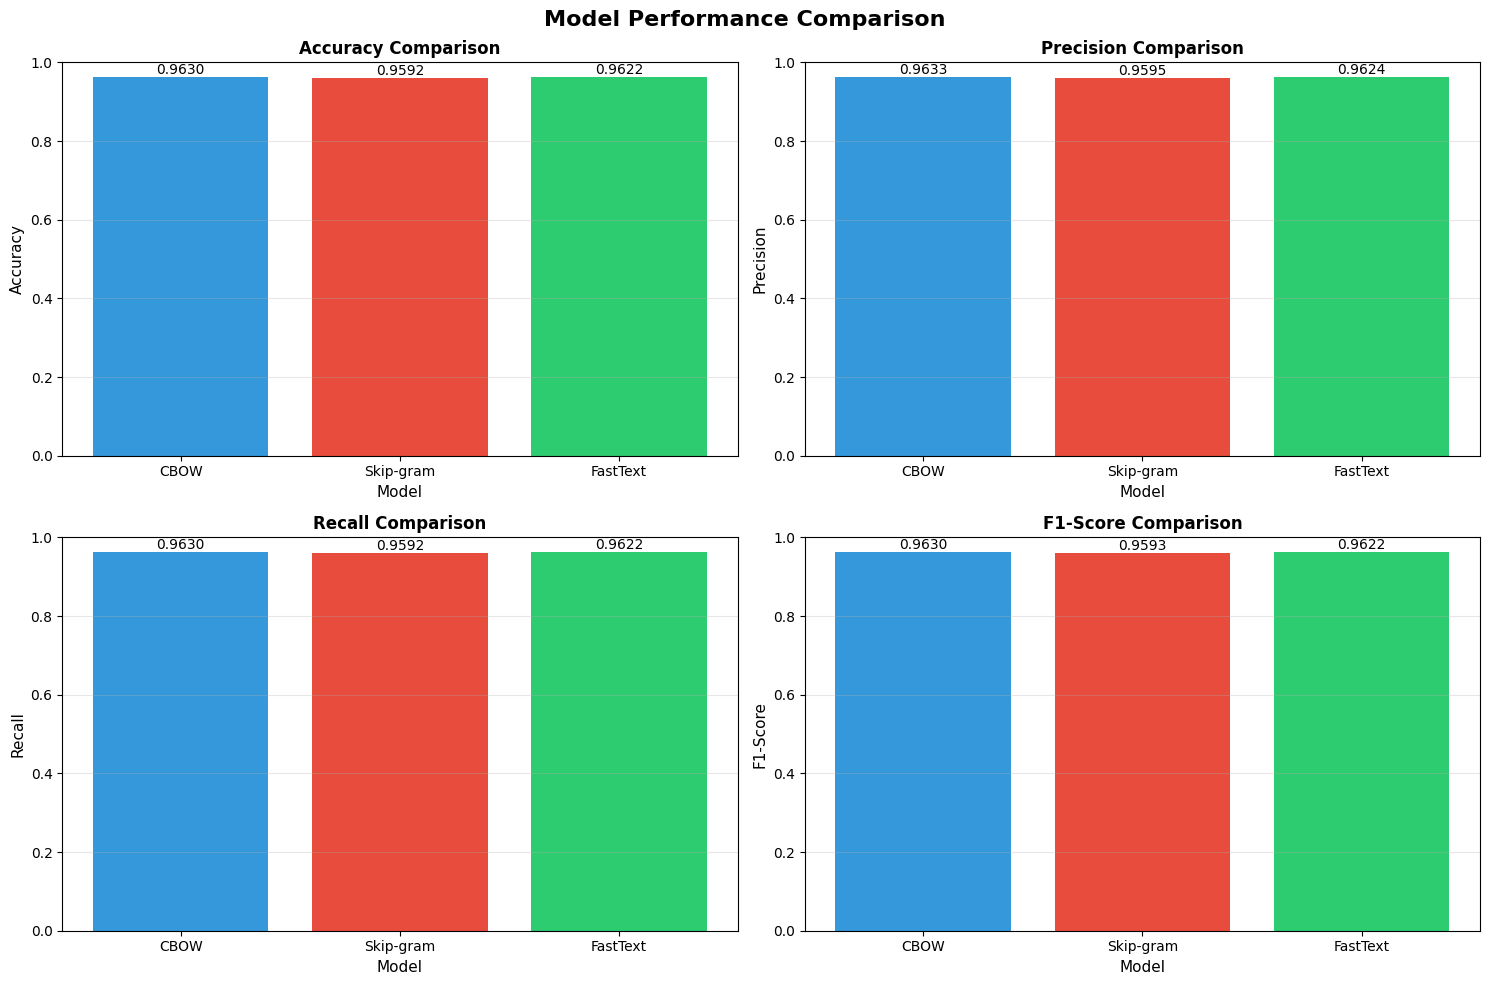


🏆 Best Model: Word2Vec CBOW + GRU
   F1-Score: 0.9630


In [ ]:
comparison_df = pd.DataFrame([
    {
        'Model': 'Word2Vec CBOW + GRU',
        'Accuracy': results_cbow['accuracy'],
        'Precision': results_cbow['precision'],
        'Recall': results_cbow['recall'],
        'F1-Score': results_cbow['f1_score']
    },
    {
        'Model': 'Word2Vec Skip-gram + GRU',
        'Accuracy': results_skipgram['accuracy'],
        'Precision': results_skipgram['precision'],
        'Recall': results_skipgram['recall'],
        'F1-Score': results_skipgram['f1_score']
    },
    {
        'Model': 'FastText + GRU',
        'Accuracy': results_fasttext['accuracy'],
        'Precision': results_fasttext['precision'],
        'Recall': results_fasttext['recall'],
        'F1-Score': results_fasttext['f1_score']
    }
])

print("\n" + "=" * 80)
print("MODEL COMPARISON TABLE")
print("=" * 80)
print(comparison_df.to_string(index=False))
print("=" * 80)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Model Performance Comparison', fontsize=16, fontweight='bold')

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
colors = ['#3498db', '#e74c3c', '#2ecc71']

for idx, metric in enumerate(metrics):
    ax = axes[idx // 2, idx % 2]
    values = comparison_df[metric].values
    bars = ax.bar(range(len(comparison_df)), values, color=colors)
    ax.set_xlabel('Model', fontsize=11)
    ax.set_ylabel(metric, fontsize=11)
    ax.set_title(f'{metric} Comparison', fontsize=12, fontweight='bold')
    ax.set_xticks(range(len(comparison_df)))
    ax.set_xticklabels(['CBOW', 'Skip-gram', 'FastText'], rotation=0)
    ax.set_ylim([0, 1])
    ax.grid(axis='y', alpha=0.3)

    for i, (bar, val) in enumerate(zip(bars, values)):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{val:.4f}',
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

best_model_idx = comparison_df['F1-Score'].idxmax()
best_model_name = comparison_df.loc[best_model_idx, 'Model']
best_f1 = comparison_df.loc[best_model_idx, 'F1-Score']

print(f"\n🏆 Best Model: {best_model_name}")
print(f"   F1-Score: {best_f1:.4f}")

## 10. Visualize Training History

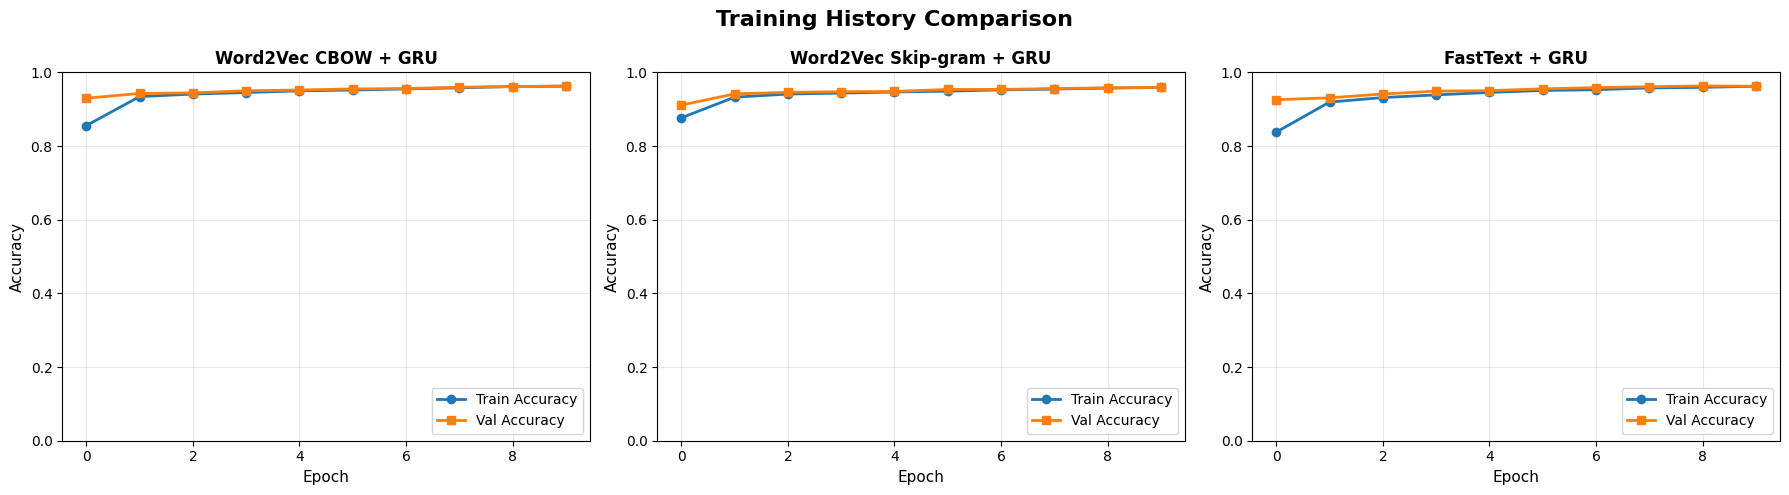

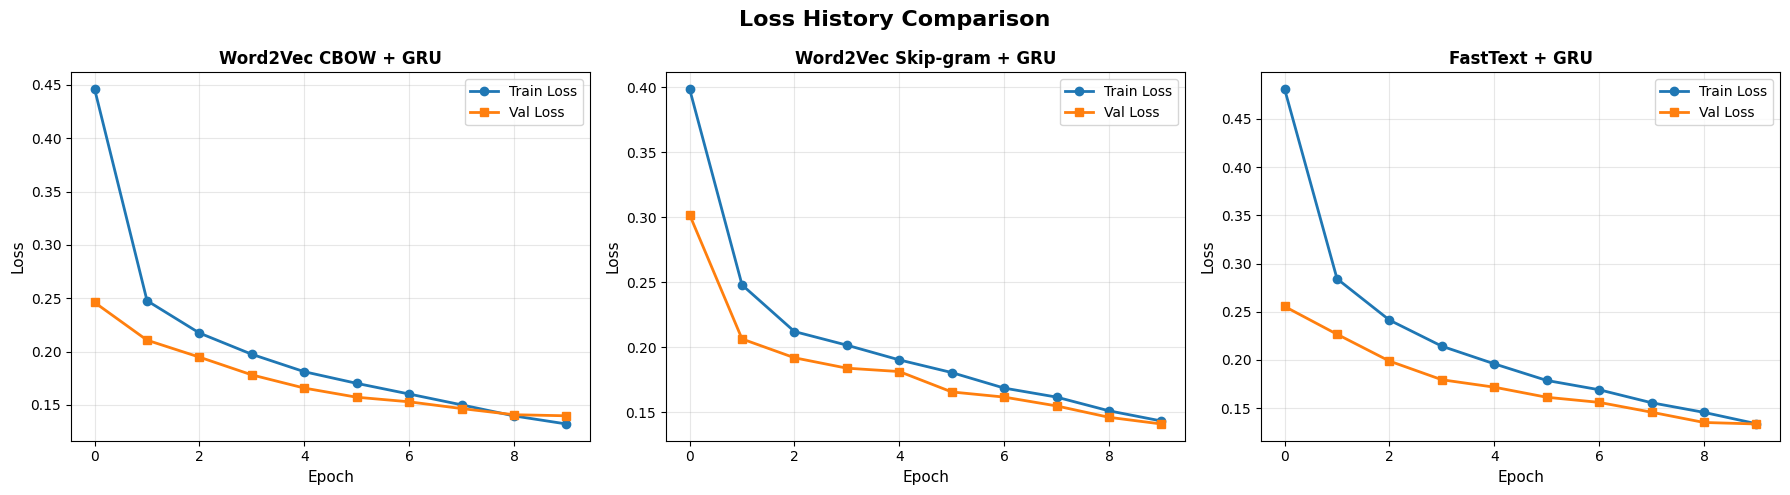

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Training History Comparison', fontsize=16, fontweight='bold')

histories = [
    (history_cbow, 'Word2Vec CBOW + GRU'),
    (history_skipgram, 'Word2Vec Skip-gram + GRU'),
    (history_fasttext, 'FastText + GRU')
]

for idx, (history, title) in enumerate(histories):
    ax = axes[idx]

    ax.plot(history.history['accuracy'], label='Train Accuracy', marker='o', linewidth=2)
    ax.plot(history.history['val_accuracy'], label='Val Accuracy', marker='s', linewidth=2)

    ax.set_xlabel('Epoch', fontsize=11)
    ax.set_ylabel('Accuracy', fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(loc='lower right')
    ax.grid(alpha=0.3)
    ax.set_ylim([0, 1])

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Loss History Comparison', fontsize=16, fontweight='bold')

for idx, (history, title) in enumerate(histories):
    ax = axes[idx]

    ax.plot(history.history['loss'], label='Train Loss', marker='o', linewidth=2)
    ax.plot(history.history['val_loss'], label='Val Loss', marker='s', linewidth=2)

    ax.set_xlabel('Epoch', fontsize=11)
    ax.set_ylabel('Loss', fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(loc='upper right')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Confusion Matrices

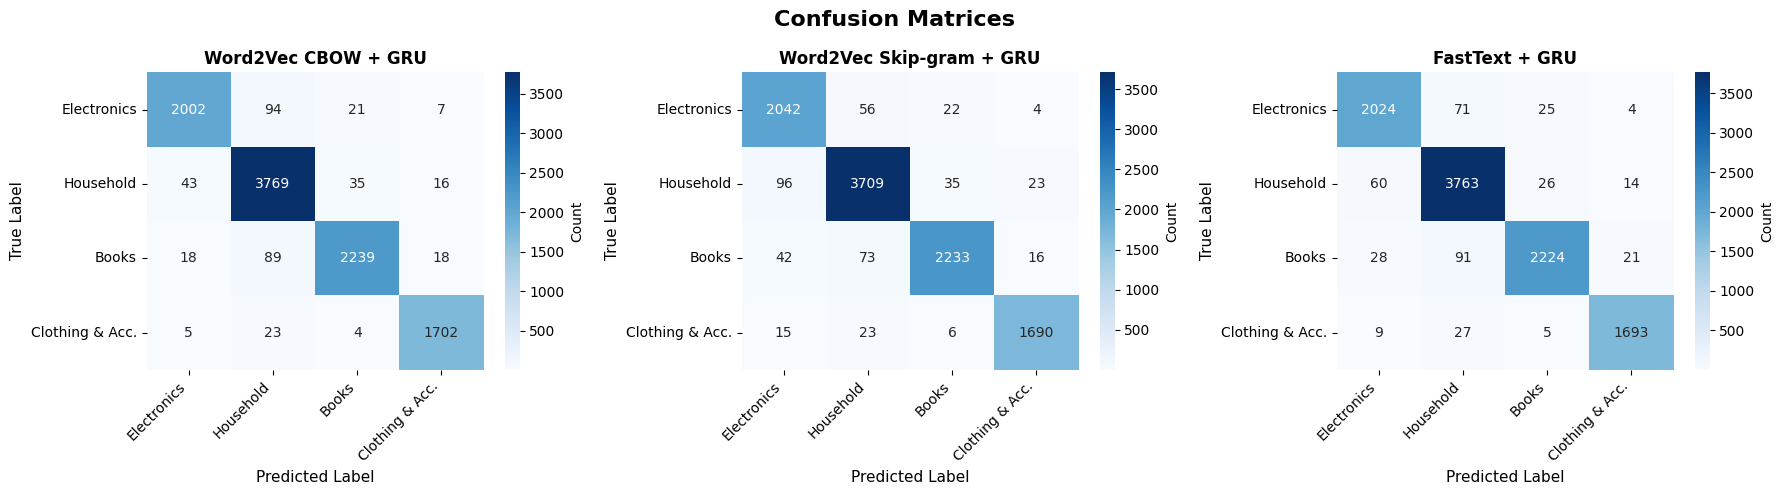

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Confusion Matrices', fontsize=16, fontweight='bold')

class_names = ['Electronics', 'Household', 'Books', 'Clothing & Acc.']
results_list = [results_cbow, results_skipgram, results_fasttext]

for idx, (ax, results) in enumerate(zip(axes, results_list)):
    cm = confusion_matrix(results['true_labels'], results['predictions'])

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'label': 'Count'})

    ax.set_xlabel('Predicted Label', fontsize=11)
    ax.set_ylabel('True Label', fontsize=11)
    ax.set_title(results['model'], fontsize=12, fontweight='bold')

    # Rotate x-axis labels for better readability
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.set_yticklabels(class_names, rotation=0)

plt.tight_layout()
plt.show()

## 12. Test Predictions on Sample Texts

In [ ]:
def predict_category(text, model, model_name):
    """
    Predicts the category of a given product description.

    Args:
        text: Product description text
        model: Trained model
        model_name: Name of the model

    Returns:
        Predicted category and confidence
    """
    cleaned = preprocess_text(text)

    sequence = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(sequence, maxlen=MAX_SEQUENCE_LENGTH, padding='post', truncating='post')

    prediction = model.predict(padded, verbose=0)
    predicted_class = np.argmax(prediction[0])
    confidence = prediction[0][predicted_class]

    reverse_mapping = {v: k for k, v in category_mapping.items()}
    category = reverse_mapping[predicted_class]

    return category, confidence

test_samples = [
    "Samsung Galaxy S21 5G smartphone with 128GB storage and AMOLED display",
    "The Great Gatsby by F. Scott Fitzgerald, classic American novel",
    "Black cotton t-shirt with round neck, size medium",
    "Stainless steel cooking pot set with non-stick coating"
]

print("=" * 80)
print("SAMPLE PREDICTIONS")
print("=" * 80)

for sample in test_samples:
    print(f"\nText: {sample}")
    print("-" * 80)

    cat_cbow, conf_cbow = predict_category(sample, model_cbow, "CBOW")
    cat_skip, conf_skip = predict_category(sample, model_skipgram, "Skip-gram")
    cat_fast, conf_fast = predict_category(sample, model_fasttext, "FastText")

    print(f"  CBOW:      {cat_cbow:30s} (confidence: {conf_cbow:.4f})")
    print(f"  Skip-gram: {cat_skip:30s} (confidence: {conf_skip:.4f})")
    print(f"  FastText:  {cat_fast:30s} (confidence: {conf_fast:.4f})")

print("\n" + "=" * 80)

SAMPLE PREDICTIONS

Text: Samsung Galaxy S21 5G smartphone with 128GB storage and AMOLED display
--------------------------------------------------------------------------------
  CBOW:      Electronics                    (confidence: 0.9727)
  Skip-gram: Electronics                    (confidence: 0.9924)
  FastText:  Electronics                    (confidence: 0.9907)

Text: The Great Gatsby by F. Scott Fitzgerald, classic American novel
--------------------------------------------------------------------------------
  CBOW:      Books                          (confidence: 0.9901)
  Skip-gram: Books                          (confidence: 0.9632)
  FastText:  Books                          (confidence: 0.9899)

Text: Black cotton t-shirt with round neck, size medium
--------------------------------------------------------------------------------
  CBOW:      Clothing & Accessories         (confidence: 0.9984)
  Skip-gram: Clothing & Accessories         (confidence: 0.9984)
  FastText: 

In [ ]:
# Save results to CSV for future reference
comparison_df.to_csv('model_comparison_results.csv', index=False)
print("Results saved to 'model_comparison_results.csv'")

# Display final summary
print("\n" + "=" * 80)
print("EXPERIMENT COMPLETE")
print("=" * 80)
print(f"\nTotal training samples: {len(X_train)}")
print(f"Total validation samples: {len(X_val)}")
print(f"Vocabulary size: {len(tokenizer.word_index)}")
print(f"Embedding dimension: {EMBEDDING_DIM}")
print(f"Max sequence length: {MAX_SEQUENCE_LENGTH}")
print(f"Number of classes: {NUM_CLASSES}")
print("\nAll three models trained and evaluated successfully!")
print("=" * 80)

Results saved to 'model_comparison_results.csv'

EXPERIMENT COMPLETE

Total training samples: 40340
Total validation samples: 10085
Vocabulary size: 89578
Embedding dimension: 100
Max sequence length: 50
Number of classes: 4

All three models trained and evaluated successfully!
